## Dataset and common setup. 
*   Use fetch olivetti faces: 40 identities, 10 images per identity, each 64 × 64. 
*   Use all numeric characters of your complete roll number, in order, as the seed for numpy.random.default rng.
    *  My Roll No. is M26CSA006, Using seed = 26006
*   For the robustness experiment, create a second test set by setting the centred 16 × 16 block, rows and columns 24 to 39, to zero. Models must still be trained only on clean images.

CREDIT - AT&T Laboratories Cambridge for the dataset

In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn import metrics
import joblib
from joblib import Parallel, delayed
from time import perf_counter

In [2]:
from sklearn.datasets import fetch_olivetti_faces
olivetti_faces = fetch_olivetti_faces(
    data_home="data",
    download_if_missing=True
)

In [3]:
olivetti_faces.data

array([[0.30991736, 0.3677686 , 0.41735536, ..., 0.15289256, 0.16115703,
        0.1570248 ],
       [0.45454547, 0.47107437, 0.5123967 , ..., 0.15289256, 0.15289256,
        0.15289256],
       [0.3181818 , 0.40082645, 0.49173555, ..., 0.14049587, 0.14876033,
        0.15289256],
       ...,
       [0.5       , 0.53305787, 0.607438  , ..., 0.17768595, 0.14876033,
        0.19008264],
       [0.21487603, 0.21900827, 0.21900827, ..., 0.57438016, 0.59090906,
        0.60330576],
       [0.5165289 , 0.46280992, 0.28099173, ..., 0.35950413, 0.3553719 ,
        0.38429752]], shape=(400, 4096), dtype=float32)

In [4]:
rng = np.random.default_rng(seed=26006)


In [5]:
X_train, y_train = [], []
X_valid, y_valid = [], []
X_test, y_test = [], []
for identity in range(40):
    # Get the indices of the images for this identity
    indices = np.where(olivetti_faces.target == identity)[0]
    # Shuffle the indices
    rng.shuffle(indices)
    # Split the indices into train, validation, and test sets
    train_indices = indices[:6]
    valid_indices = indices[6:8]
    test_indices = indices[8:]
    
    # Append the images and labels to the respective lists
    X_train.append(olivetti_faces.data[train_indices])
    y_train.append(olivetti_faces.target[train_indices])
    
    X_valid.append(olivetti_faces.data[valid_indices])
    y_valid.append(olivetti_faces.target[valid_indices])
    
    X_test.append(olivetti_faces.data[test_indices])
    y_test.append(olivetti_faces.target[test_indices])

X_train = np.vstack(X_train)
y_train = np.concatenate(y_train, axis=0)
X_valid = np.vstack(X_valid)
y_valid = np.concatenate(y_valid, axis=0)
X_test = np.vstack(X_test)
y_test = np.concatenate(y_test, axis=0)

In [6]:
X_train.shape

(240, 4096)

In [7]:
# Saving training, validation, and test sets to .npy files
np.savez('data/X_train.npy', X_train=X_train, y_train=y_train)
np.savez('data/X_valid.npy', X_valid=X_valid, y_valid=y_valid)
np.savez('data/X_test.npy', X_test=X_test, y_test=y_test)

### Question 1
Q1. Decision tree baseline and bagging from scratch - 
*   (a) First establish a single tree baseline. Train DecisionTreeClassifier models with max depth∈ {2, 4, 8, 16, None}
and min samples leaf∈ {1, 2, 4}. Select one setting using validation accuracy only and freeze it. Report train,
validation and test accuracy, number of leaves, mean samples per leaf and the fraction of leaves containing only
one training example. Explain what changes as depth increases.
*   (b) Implement bagging yourself using bootstrap samples of the original training set size and the frozen tree setting
from part (a). Use B ∈ {1, 5, 10, 25, 50, 100, 200}. For every B, report train, validation and test accuracy and the
average number of distinct examples in one bootstrap sample. Compare the last quantity with its theoretical
expectation.
*   (c) For every B, compute out of bag accuracy, average pairwise disagreement between trees, and mean vote margin,
where vote margin is the winning vote fraction minus the runner up vote fraction. Plot all three against B. Select
one final ensemble size using the validation set and explain whether out of bag accuracy, disagreement and vote
margin tell the same story.
*   (d) Compare the frozen single tree and the final bagged model on both the clean and masked test sets. Report
accuracy and prediction confidence for both. Find two faces where bagging corrects the tree and two where both
are wrong. Show the tree prediction and bagging vote counts, and use these cases to explain what type of error
bagging can reduce and what type it cannot.

Let's solve Q1(a)-

In [8]:
from sklearn.tree import DecisionTreeClassifier

In [9]:
def evaluate_model(max_depth, min_samples_leaf, X_train, y_train, X_val, y_val):
    model = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=42)
    model.fit(X_train, y_train)
    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)
    return {'Max Depth':max_depth, 'Min Samples Leaf':min_samples_leaf, 'Training Accuracy':train_acc, 'Validation Accuracy':val_acc}

In [10]:
max_depths = [2, 4, 8, 16, None]
min_samples_leaves = [1, 2, 4]

results = []
for max_depth in max_depths:
    for min_samples_leaf in min_samples_leaves:
        results.append(evaluate_model(
            max_depth = max_depth,
            min_samples_leaf = min_samples_leaf,
            X_train = X_train,
            y_train = y_train,
            X_val = X_valid,
            y_val = y_valid
        ))
results_df = pd.DataFrame(results)

In [11]:
results_df

,Max Depth,Min Samples Leaf,Training Accuracy,Validation Accuracy
0,2.0,1,0.075000,0.0750
1,2.0,2,0.075000,0.0750
2,2.0,4,0.075000,0.0750
3,4.0,1,0.125000,0.1000
4,4.0,2,0.125000,0.1000
5,4.0,4,0.125000,0.1000
6,8.0,1,0.225000,0.1750
7,8.0,2,0.225000,0.1750
8,8.0,4,0.225000,0.1750
9,16.0,1,0.450000,0.3125


As can be seen above, that max_depth=None is able to achieve heighest accuracy, but instead of taking 1 min. leaf node, 2 is a better choice, since the model is able to tradeoff between the training andvalidation accuracy.   

In [12]:
# Train a Decision Tree model with the best hyperparameters found
baselineModel = DecisionTreeClassifier(max_depth=None, min_samples_leaf=2, random_state=42)
baselineModel.fit(X_train, y_train)

DecisionTreeClassifier(min_samples_leaf=2, random_state=42)

In [13]:
# Saving the baseline model to Models/baseline_model.joblib
joblib.dump(baselineModel, 'Models/baseline_model.joblib')

# saving configuration metadata for reproducability
config = {
    "baseline_max_depth": None,
    "baseline_min_samples_leaf": 2,
}

joblib.dump(config, "Models/model_config.joblib")

['Models/model_config.joblib']

In [14]:
baselineModel.tree_.n_node_samples

array([240,   6, 234,   6, 228, 222, 216,   6, 210,   6, 204, 198, 192,
       186,   6, 180,   6, 174,   6, 168,   6, 162,   6, 156,  15,   6,
         9,   6,   3, 141, 134,   7,   5,   2, 127,   7,   5,   2, 120,
         6, 114,   6, 108,   6, 102,   7,   5,   2,  95,  74,  68,  49,
         6,  43,   7,   5,   2,  36,   5,  31,  24,   5,  19,   5,  14,
         5,   9,   4,   5,   2,   3,   7,   2,   5,  19,   6,  13,   6,
         7,   2,   5,   6,  21,   6,  15,   6,   9,   5,   4,   7,   2,
         5,   6,   6,   6,   6,   6])

In [15]:
# Report for the baseline model
train_acc = baselineModel.score(X_train, y_train)
val_acc = baselineModel.score(X_valid, y_valid)
test_acc = baselineModel.score(X_test, y_test)
number_of_leaves = baselineModel.get_n_leaves()

# Identify the leaf nodes
tree = baselineModel.tree_
leaf_mask = (tree.children_left == -1) & (tree.children_right == -1)
# Get the number of samples in each leaf node
samples_per_leaf = tree.n_node_samples[leaf_mask]

# Required statistics
mean_samples_per_leaf = np.mean(samples_per_leaf)
singleton_leaf_fraction = np.mean(samples_per_leaf == 1)

print(
    f"Baseline Model Report:\n"
    f"Training Accuracy: {train_acc*100:.4f}\n"
    f"Validation Accuracy: {val_acc*100:.4f}\n"
    f"Test Accuracy: {test_acc*100:.4f}\n"
    f"Number of Leaves: {number_of_leaves}\n"
    f"Mean Samples per Leaf: {mean_samples_per_leaf:.4f}\n"
    f"Singleton Leaf Fraction: {singleton_leaf_fraction:.4f}\n"
)

Baseline Model Report:
Training Accuracy: 96.6667
Validation Accuracy: 58.7500
Test Accuracy: 55.0000
Number of Leaves: 49
Mean Samples per Leaf: 4.8980
Singleton Leaf Fraction: 0.0000



As the depth increase, following observations can be made -
*   The training accuracy increases, as the tree creates more decision boundaries
*   Tree initially learns useful patterns, which can be seen in valiation accuracy, but with more increase in depth, the tree starts leaning data speicific patterns that doesn't generealize well to unseen data.
*   The gap between the training and the validation accuracy showcase the generalization problem. As can be seen that the unrestricted tree with `min_samples_leaf=1` reached 100% training accuracy but only 53.75% validation accuracy.
*   Increasing `min_samples_leaf` prevents the tree from creating leaves with very few samples, which in turn reduces overfitting. Our selected model (min_samples_leaf=2, max_depth=None) achieved 58.75% validation accuracy.

Q1(b) Implement bagging yourself using bootstrap samples of the original training set size and the frozen tree setting from part (a). Use B ∈ {1, 5, 10, 25, 50, 100, 200}. For every B, report train, validation and test accuracy and the
average number of distinct examples in one bootstrap sample. Compare the last quantity with its theoretical expectation.

In [16]:
def bagging(X_train, y_train, n_estimators, rng):
    trees = []
    distinct_counts = []
    n_samples_indices = []
    n_samples = X_train.shape[0]

    for i in range(n_estimators):
        # 1. Draw a bootstrap sample of the original training size
        sample_indices = rng.choice(
            X_train.shape[0],
            size=n_samples,
            replace=True
        )

        n_distinct = len(np.unique(sample_indices))
        distinct_counts.append(n_distinct)
        n_samples_indices.append(sample_indices)

        # 2. Generate a reproducible seed for this tree
        tree_seed = rng.integers(0, 2**31 - 1)

        # 3. Train a Decision Tree on the boostrap sample
        model = DecisionTreeClassifier(max_depth=None, min_samples_leaf=2, random_state=tree_seed)
        model.fit(X_train[sample_indices], y_train[sample_indices])
        
        trees.append(model)

    return {"trees": trees, "Data_indices": n_samples_indices, "distinct_counts": distinct_counts}

In [17]:
def get_bagging_votes(trees, X):
    """
    DESCR:
        -   A utitlity function to determine class for each sample using each Decision Tree in Ensemble

    ARGS:
        -   trees: Ensemble of Decision trees
        -   X: Features of dataset

    RETURNS:
        -   A matrix of shape (No. of samples in X, No. of trees)
    """
    return np.array([tree.predict(X) for tree in trees]).T

In [18]:
def predict_bagging(trees, X):
    """
    DESCR:
        -   A utitlity function to determine class for each sample using majority voting among all the decision trees
        present in the ensemble

    ARGS:
        -   trees: Ensemble of Decision trees
        -   X: Features of dataset

    RETURNS:
        -   Class predicted by the majority voting among tress in bagged ensemble
    """
    # Each row corresponds to one tree's predictions
    preds = get_bagging_votes(trees, X)

    # Select the most-voted class for each example
    y_pred = np.array([
        np.argmax(np.bincount(votes))
        for votes in preds
    ])

    return y_pred

In [19]:
def evaluate_bagging(trees, X_train, y_train, X_val, y_val, X_test, y_test):
    """
    DESCR:
        - A utility funciton to evaluate model for training, validation and test dataset.
    
    ARGS:
        - trees: Ensemble of Decision trees\
        - X_train: Features for training dataset
        - y_train: label for training dataset
        - X_val: Features for validation dataset
        - y_train: label for validation dataset
        - X_test: Features for testing dataset
        - y_train: label for validation dataset

    RETURNS:
        A dictionary containing
        - train_acc
        - val_acc
        - test_acc
    """
    # Training Accuracy
    train_acc = np.mean(y_train == predict_bagging(trees, X_train))

    # Validation Accuracy
    val_acc = np.mean(y_val == predict_bagging(trees, X_val))

    # Testing Accuracy
    test_acc = np.mean(y_test == predict_bagging(trees, X_test))
    
    return {"train_acc": train_acc, "val_acc": val_acc, "test_acc": test_acc}

In [20]:
B_max_size = 200
B_size = [1, 5, 10, 25, 50, 100, 200]

bagging_result = bagging(X_train, y_train, n_estimators=B_max_size, rng=np.random.default_rng(seed=26006))
trees = bagging_result["trees"]
distinct_counts = bagging_result["distinct_counts"]

Bagging_results = []
for B in B_size:
    Bagging_results.append(evaluate_bagging(
        trees = trees[:B],
        X_train = X_train,
        y_train = y_train,
        X_val = X_valid,
        y_val = y_valid,
        X_test = X_test,
        y_test = y_test
    ))
    Bagging_results[-1]["Avg Distinct Samples"] = np.mean(distinct_counts[:B])
results_df = pd.DataFrame(Bagging_results, index=B_size)

In [21]:
results_df

,train_acc,val_acc,test_acc,Avg Distinct Samples
1,0.675000,0.4750,0.3750,145.000
5,0.929167,0.5875,0.6625,150.600
10,1.000000,0.7375,0.7625,151.800
25,1.000000,0.8500,0.7875,151.840
50,1.000000,0.9000,0.8125,151.860
100,1.000000,0.8875,0.8375,152.110
200,1.000000,0.9000,0.8625,151.725


In [22]:
n = X_train.shape[0]

theoretical_distinct = n * (1 - (1 - 1/n)**n)
print("Theoretical expectation:", theoretical_distinct)

Theoretical expectation: 151.8931938460841


(c) For every B, compute out of bag accuracy, average pairwise disagreement between trees, and mean vote margin,
where vote margin is the winning vote fraction minus the runner up vote fraction. Plot all three against B. Select
one final ensemble size using the validation set and explain whether out of bag accuracy, disagreement and vote
margin tell the same story. 

In [23]:
def oob_accuracy(trees, bootstrap_indices, X_train, y_train):
    oob_votes = [[] for _ in range(len(y_train))]

    for i in range(len(trees)):
        tree = trees[i]
        sample_indices = bootstrap_indices[i]

        oob_mask = np.ones(X_train.shape[0], dtype=bool)
        oob_mask[sample_indices] = False  # Mark the bootstrap sample indices as False

        X_oob = X_train[oob_mask]
        y_oob = y_train[oob_mask]
        y_pred_oob = tree.predict(X_oob)

        oob_indices = np.flatnonzero(oob_mask)

        for idx, pred in zip(oob_indices, y_pred_oob):
            oob_votes[idx].append(pred)

    # Calculate the OOB accuracy
    correct_predictions = 0
    total_oob_samples = 0
    for i in range(len(y_train)):
        if oob_votes[i]:  # If there are OOB votes for this sample
            total_oob_samples += 1
            majority_vote = np.argmax(np.bincount(oob_votes[i]))
            if majority_vote == y_train[i]:
                correct_predictions += 1
    oob_accuracy = correct_predictions / total_oob_samples if total_oob_samples > 0 else 0
    return oob_accuracy



In [24]:
oob_results = []
for B in B_size:
    oob_acc = oob_accuracy(trees[:B], bagging_result["Data_indices"][:B], X_train, y_train)
    oob_results.append({"B": B, "OOB Accuracy": oob_acc})
oob_results_df = pd.DataFrame(oob_results)
oob_results_df

,B,OOB Accuracy
0,1,0.252632
1,5,0.330233
2,10,0.379167
3,25,0.554167
4,50,0.666667
5,100,0.741667
6,200,0.787500


In [25]:
def pairwise_disagreement(trees, X):
    predictions = get_bagging_votes(trees, X)
    B = predictions.shape[1]

    if B < 2:
        return np.nan

    total_pairs = B * (B - 1) / 2
    disagreements = []

    for row in predictions:
        _, counts = np.unique(row, return_counts=True)
        agreeing = np.sum(counts * (counts - 1) / 2)
        disagreeing_pairs = total_pairs - agreeing
        disagreements.append(disagreeing_pairs / total_pairs)

    return np.mean(disagreements)

In [26]:
pairwise_results = []
for B in B_size:
    apd = pairwise_disagreement(trees[:B], X_train)
    pairwise_results.append({"B": B, "Average Pairwise Disagreement": apd})
pairwise_results_df = pd.DataFrame(pairwise_results)
pairwise_results_df

,B,Average Pairwise Disagreement
0,1,NaN
1,5,0.470833
2,10,0.483519
3,25,0.485986
4,50,0.482204
5,100,0.481305
6,200,0.480849


In [27]:
def mean_vote_margin(trees, X):
    predictions = get_bagging_votes(trees, X)
    B = predictions.shape[1]

    margins = []

    for row in predictions:
        # 1. Count votes for each class.
        votes = np.bincount(row, minlength=40)  # Assuming 40 classes

        # 2. Find the largest and second-largest vote counts.
        sorted_votes = np.sort(votes)[::-1]
        largest = sorted_votes[0]
        second_largest = sorted_votes[1] if len(sorted_votes) > 1 else 0

        # 3. Divide each count by B.
        winning_fraction = largest / B
        runner_up_fraction = second_largest / B

        # 4. Subtract runner-up fraction from winning fraction.
        margin = winning_fraction - runner_up_fraction

        # 5. Append this example's margin.
        margins.append(margin)

    return np.mean(margins)

In [28]:
mean_votes_results = []
for B in B_size:
    margin = mean_vote_margin(trees[:B], X_train)
    mean_votes_results.append({"B": B, "Mean Vote Margin": margin})
mean_votes_results_df = pd.DataFrame(mean_votes_results)
mean_votes_results_df

,B,Mean Vote Margin
0,1,1.000000
1,5,0.555000
2,10,0.590417
3,25,0.627500
4,50,0.646083
5,100,0.653667
6,200,0.659771


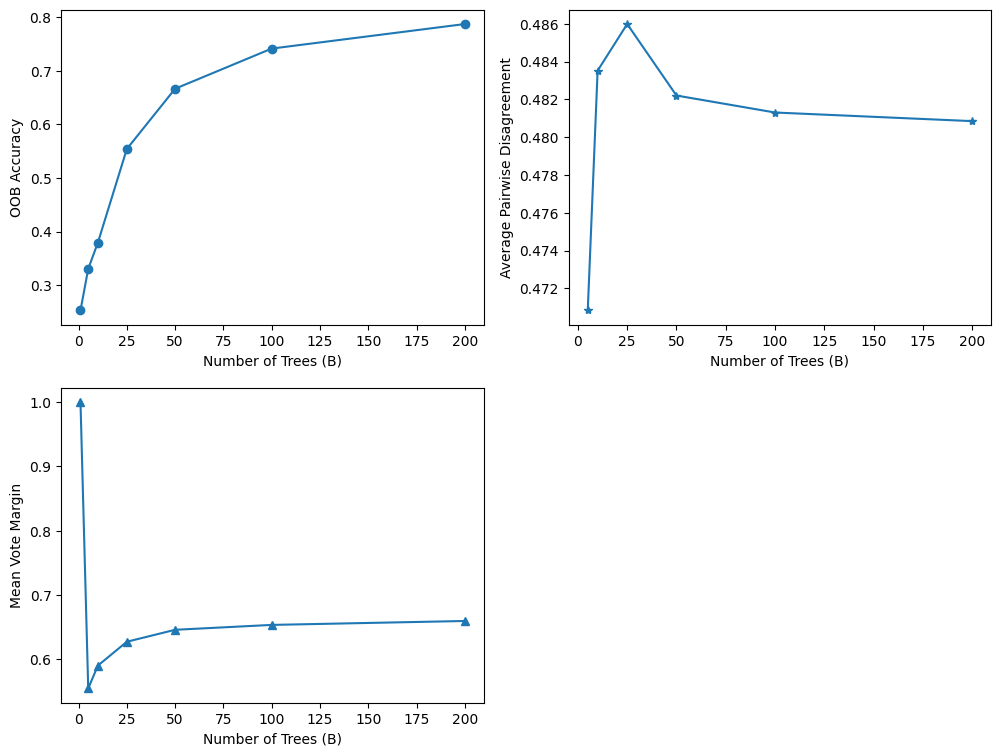

In [29]:
plt.figure(figsize=(12, 9))
plt.subplot(2,2,1)
plt.plot(oob_results_df["B"], oob_results_df["OOB Accuracy"], marker='o')
plt.xlabel('Number of Trees (B)')
plt.ylabel("OOB Accuracy")

plt.subplot(2,2,2)
plt.plot(pairwise_results_df["B"], pairwise_results_df["Average Pairwise Disagreement"], marker='*', label='Average Pairwise Disagreement')
plt.xlabel('Number of Trees (B)')
plt.ylabel("Average Pairwise Disagreement")

plt.subplot(2,2,3)
plt.plot(mean_votes_results_df["B"], mean_votes_results_df["Mean Vote Margin"], marker='^', label="Mean Vote Margin")
plt.xlabel('Number of Trees (B)')
plt.ylabel('Mean Vote Margin')

plt.show()


In [30]:
results_df

,train_acc,val_acc,test_acc,Avg Distinct Samples
1,0.675000,0.4750,0.3750,145.000
5,0.929167,0.5875,0.6625,150.600
10,1.000000,0.7375,0.7625,151.800
25,1.000000,0.8500,0.7875,151.840
50,1.000000,0.9000,0.8125,151.860
100,1.000000,0.8875,0.8375,152.110
200,1.000000,0.9000,0.8625,151.725


As can be seen in above samples, that bagged ensemble of 50 decision tress, is able to achieve same validation accuracy as ensemble of 200 decision trees. Thus, finalizing the ensemble of 50 Decision trees, as the final ensemble model.

In [31]:
# Saving model to local dir ./Models
final_B = 50

# using first 50 trees from existing ensemble trees
final_bagged_trees = trees[:final_B]

joblib.dump(final_bagged_trees, 'Models/bagging_model_B50.joblib')

# Save configuration metadata for reproducibility
config = {
    "baseline_max_depth": None,
    "baseline_min_samples_leaf": 2,
    "bagging_max_depth": None,
    "bagging_min_samples_leaf": 2,
    "bagging_n_estimators": 50,
    "random_seed": 26006,
}

joblib.dump(config, "Models/model_config.joblib")


['Models/model_config.joblib']

(d) Compare the frozen single tree and the final bagged model on both the clean and masked test sets. Report
accuracy and prediction confidence for both. Find two faces where bagging corrects the tree and two where both
are wrong. Show the tree prediction and bagging vote counts, and use these cases to explain what type of error
bagging can reduce and what type it cannot.

In [32]:
def bagging_confidence(trees, X):
    votes = get_bagging_votes(trees, X)
    confidence = []

    for row in votes:
        counts = np.bincount(row, minlength=40)
        confidence.append(counts.max() / len(trees))

    return np.array(confidence)

In [33]:
X_masked_test = X_test.reshape(-1, 64, 64).copy()

X_masked_test[:, 24:40, 24:40] = 0

X_masked_test = X_masked_test.reshape(-1, 4096)
X_masked_test.shape

(80, 4096)

In [34]:

# Q1(d): Accuracy and prediction confidence
# Clean test set
base_clean_accuracy = baselineModel.score(X_test, y_test)
base_clean_confidence = baselineModel.predict_proba(X_test).max(axis=1).mean()

bagged_clean_preds = predict_bagging(final_bagged_trees, X_test)
bagged_clean_accuracy = np.mean(bagged_clean_preds == y_test)
bagged_clean_confidence = bagging_confidence(final_bagged_trees, X_test).mean()

# Masked test set
base_masked_accuracy = baselineModel.score(X_masked_test, y_test)
base_masked_confidence = baselineModel.predict_proba(X_masked_test).max(axis=1).mean()

bagged_masked_preds = predict_bagging(final_bagged_trees, X_masked_test)
bagged_masked_accuracy = np.mean(bagged_masked_preds == y_test)
bagged_masked_confidence = bagging_confidence(
    final_bagged_trees, X_masked_test
).mean()

# Results table
comparison_df = pd.DataFrame({
    "Model": ["Single Tree", "Bagging (B=50)"],
    "Clean Accuracy": [base_clean_accuracy, bagged_clean_accuracy],
    "Clean Mean Confidence": [
        base_clean_confidence, bagged_clean_confidence
    ],
    "Masked Accuracy": [base_masked_accuracy, bagged_masked_accuracy],
    "Masked Mean Confidence": [
        base_masked_confidence, bagged_masked_confidence
    ]
})

comparison_df


,Model,Clean Accuracy,Clean Mean Confidence,Masked Accuracy,Masked Mean Confidence
0,Single Tree,0.5500,0.9750,0.300,0.9500
1,Bagging (B=50),0.8125,0.3885,0.575,0.2805


The bagged ensemble outperformed the single decision tree on both clean and masked test images. Its accuracy was 81.25% on clean images and 57.5% on masked images, compared with 55% and 30% for the single tree. The single tree maintained high mean predicted probability even after masking, despite a substantial decline in accuracy. In contrast, the ensemble's mean winning vote fraction decreased under masking, indicating greater disagreement among its constituent trees. These results illustrate that prediction confidence and prediction accuracy are distinct, and that aggregating trees can improve classification performance without guaranteeing robustness to input corruption.

In [35]:
# Prediction on the clean test set
tree_preds = baselineModel.predict(X_test)
bagging_preds = predict_bagging(final_bagged_trees, X_test)

# Case 1: Tree is wrong, but bagging is correct
correct_mask = (tree_preds != y_test) & (bagging_preds == y_test)
correct_indices = np.where(correct_mask)[0]

print("Indices where bagging corrects the tree:", correct_indices)
print("True labels:", y_test[correct_indices])
print("Tree Predictions:", tree_preds[correct_indices])
print("Bagging predictions:", bagging_preds[correct_indices])

# Select two examples
two_corrected = correct_indices[:2]

Indices where bagging corrects the tree: [ 0  1  2  3  4 14 23 27 31 32 33 34 36 41 50 51 52 53 54 57 60 62 63 73
 79]
True labels: [ 0  0  1  1  2  7 11 13 15 16 16 17 18 20 25 25 26 26 27 28 30 31 31 36
 39]
Tree Predictions: [ 4 20  0 17 16 11  9  4  0  8 25 15 10 39 24  4  1 12  3 38 14 35 14 27
 27]
Bagging predictions: [ 0  0  1  1  2  7 11 13 15 16 16 17 18 20 25 25 26 26 27 28 30 31 31 36
 39]


In [36]:
# Case 2: Where both models are wrong
both_wrong_mask = (tree_preds != y_test) & (bagging_preds != y_test)
both_wrong_indices = np.where(both_wrong_mask)[0]

print("Indices where both models are wrong:", both_wrong_indices)
print("True labels:", y_test[both_wrong_indices])
print("Tree predictions:", tree_preds[both_wrong_indices])
print("Bagging predictions:", bagging_preds[both_wrong_indices])

# Select two examples:
two_both_wrong = both_wrong_indices[:2]

Indices where both models are wrong: [ 7  8 17 19 30 45 46 48 68 69 75]
True labels: [ 3  4  8  9 15 22 23 24 34 34 37]
Tree predictions: [38  0 17 11  5 24 14 25  2  8  4]
Bagging predictions: [ 2 39  9  7  5 24 15 22 39 21  4]


In [37]:
# For each selected face, we need it's true identity, the tree's predictions, and the ensemble's votes for it's predicted identity
def show_vote_counts(indices, X, y_true, tree_preds, trees):
    all_votes = get_bagging_votes(trees, X)

    for idx in indices:
        votes = all_votes[idx]
        counts = np.bincount(votes, minlength=40)

        print(f"\nTest Index: {idx}")
        print(f"True identity: {y_true[idx]}")
        print(f"Tree prediction: {tree_preds[idx]}")
        print(f"Bagging prediction: {np.argmax(counts)}")
        print(f"Winning vote count: {counts.max()}")
        print("Non-zero class votes:",
              {i: int(c) for i,c in enumerate(counts) if c>0})

show_vote_counts(two_corrected, X_test, y_test, tree_preds, final_bagged_trees)
show_vote_counts(two_both_wrong, X_test, y_test, tree_preds, final_bagged_trees)


Test Index: 0
True identity: 0
Tree prediction: 4
Bagging prediction: 0
Winning vote count: 19
Non-zero class votes: {0: 19, 1: 1, 2: 1, 4: 1, 5: 1, 7: 1, 11: 3, 12: 2, 15: 1, 16: 1, 22: 1, 24: 1, 25: 7, 27: 2, 36: 5, 37: 2, 39: 1}

Test Index: 1
True identity: 0
Tree prediction: 20
Bagging prediction: 0
Winning vote count: 15
Non-zero class votes: {0: 15, 3: 3, 4: 1, 5: 2, 6: 2, 11: 1, 12: 1, 15: 3, 16: 2, 20: 6, 21: 1, 22: 1, 23: 3, 24: 1, 30: 2, 34: 2, 35: 3, 36: 1}

Test Index: 7
True identity: 3
Tree prediction: 38
Bagging prediction: 2
Winning vote count: 8
Non-zero class votes: {0: 3, 1: 1, 2: 8, 3: 7, 4: 1, 9: 3, 10: 2, 14: 2, 15: 2, 17: 6, 20: 1, 22: 1, 24: 4, 27: 1, 30: 1, 31: 2, 33: 1, 34: 1, 38: 3}

Test Index: 8
True identity: 4
Tree prediction: 0
Bagging prediction: 39
Winning vote count: 9
Non-zero class votes: {0: 7, 2: 4, 3: 7, 4: 2, 5: 3, 6: 1, 7: 1, 15: 4, 16: 2, 17: 2, 19: 1, 20: 1, 24: 2, 25: 1, 27: 1, 34: 1, 35: 1, 39: 9}


The key distinction is between errors that vary across trees and errors that many trees share.
- Errors bagging can reduce: An individual tree makes a mistake, but other trees predict the correct identity. Aggregating their predictions can overcome the mistake.
- Errors bagging may not reduce: Many trees make similar mistakes, or their votes collectively favor the same incorrect identity. Majority voting cannot guarantee correction.

Q2. Multiclass boosting from scratch:
Implement SAMME AdaBoost yourself. 
-   (a) Before using the face data, create a three class example with at most 10 samples. Log one complete SAMME
round: initial sample weights, weak learner predictions, weighted error, αt, and updated normalised weights.
Your implementation on the face data must use the same update rule.
-   (b) On Olivetti Faces, use weak learner depths 1, 2, 3, 4 and 10, 25, 50, 100 rounds. Select depth and rounds using
clean validation accuracy only. For the selected model, plot weighted training error, learner weight, maximum
sample weight and the total weight carried by the 10 heaviest training images over rounds.
-   (c) Compare boosting and bagging using 25, 50 and 100 learners. Report train, validation and clean test accuracy
and training time. Also inspect one training face that receives a very large boosting weight and use its prediction
history to explain why boosting repeatedly returns attention to that sample.
-   (d) Freeze the selected boosting model. Evaluate the single tree baseline, final bagged model and boosting model on
the clean and masked test sets. Report accuracy and mean winning vote or probability for each. Find one face
for which bagging and boosting respond differently to the missing region and explain the difference using tree
disagreement and boosting sample weighting.

(a) Before using the face data, create a three class example with at most 10 samples. Log one complete SAMME
round: initial sample weights, weak learner predictions, weighted error, αt, and updated normalised weights.
Your implementation on the face data must use the same update rule.

In [38]:
# Initialize sample weights
X_sample = np.array([[1], [2], [3], [4], [5], [6]])
y_sample = np.array(["A", "A", "B", "B", "C", "C"])

# Initial weights: equal importance for every sample
weights = np.ones(len(y_sample)) / len(y_sample)

# Get the week learner's predictions
predictions = np.array(["A", "A", "B", "C", "C", "B"])

incorrect = predictions != y_sample

# Calculate the weighted errors
weighted_error = weights[incorrect].sum()

# Calculate the SAMME learner weights
K = len(np.unique(y_sample))
alpha = np.log((1 - weighted_error) / weighted_error) + np.log(K - 1)

# Update the normalize weights
updated_weights = weights.copy()
updated_weights[incorrect] *= np.exp(alpha)

# Normalize so all weights sum to 1
updated_weights /= updated_weights.sum()



In [39]:

round_log = pd.DataFrame({
    "Sample": np.arange(1, len(y_sample) + 1),
    "True Class": y_sample,
    "Prediction": predictions,
    "Correct": ~incorrect,
    "Initial Weight": weights,
    "Updated Weight": updated_weights
})

print(f"Weighted error: {weighted_error:.6f}")
print(f"Alpha: {alpha:.6f}")
print(f"Sum of updated weights: {updated_weights.sum():.6f}")

round_log


Weighted error: 0.333333
Alpha: 1.386294
Sum of updated weights: 1.000000


,Sample,True Class,Prediction,Correct,Initial Weight,Updated Weight
0,1,A,A,True,0.166667,0.083333
1,2,A,A,True,0.166667,0.083333
2,3,B,B,True,0.166667,0.083333
3,4,B,C,False,0.166667,0.333333
4,5,C,C,True,0.166667,0.083333
5,6,C,B,False,0.166667,0.333333


(b) On Olivetti Faces, use weak learner depths 1, 2, 3, 4 and 10, 25, 50, 100 rounds. Select depth and rounds using
clean validation accuracy only. For the selected model, plot weighted training error, learner weight, maximum
sample weight and the total weight carried by the 10 heaviest training images over rounds.

In [60]:
def train_samme(X, y, max_depth, n_rounds, random_state=26006):
    """
    DESCR:
        - Train a multiclass SAMME boosting ensemble.

    ARGS:
        - X : array-like, shape (n_samples, n_features)
              Training features.
        - y : array-like, shape (n_samples,)
              Training labels.
        - max_depth : int
              Maximum depth of each decision tree.
        - n_rounds : int
              Maximum number of boosting rounds.
        - random_state : int
              Seed for reproducibility.

    RETURNS:
        - dict containing the trained trees, their SAMME weights (alphas),
          and per-round diagnostics.
    """
    X = np.asarray(X)
    y = np.asarray(y)

    n_samples = len(y)
    classes = np.unique(y)
    K = len(classes)

    if K < 2:
        raise ValueError("SAMME requires at least two classes.")
    if n_samples == 0:
        raise ValueError("Training data cannot be empty.")
    if len(X) != n_samples:
        raise ValueError("X and y must contain the same number of samples.")
    if n_rounds < 1:
        raise ValueError("n_rounds must be at least 1.")

    # Initially, every training sample has equal weight.
    weights = np.full(n_samples, 1.0 / n_samples)
    rng = np.random.default_rng(random_state)

    trees = []
    alphas = []
    weighted_errors = []
    max_sample_weights = []
    top10_weight_sums = []

    # A K-class random-guessing threshold for weighted error.
    random_error_threshold = 1.0 - 1.0 / K

    for t in range(n_rounds):
        tree = DecisionTreeClassifier(
            max_depth=max_depth,
            random_state=int(rng.integers(0, 2**31 - 1))
        )

        # Train the weak learner using the current sample weights.
        tree.fit(X, y, sample_weight=weights)
        predictions = tree.predict(X)

        incorrect = predictions != y
        weighted_error = float(weights[incorrect].sum())

        # Reject a learner that is no better than random guessing.
        if weighted_error >= random_error_threshold:
            break

        # Store diagnostics for this accepted learner and its round.
        weighted_errors.append(weighted_error)
        max_sample_weights.append(float(weights.max()))
        top10_weight_sums.append(
            float(np.sort(weights)[-min(10, n_samples):].sum())
        )

        trees.append(tree)

        # A perfect learner has theoretically infinite alpha.
        # Retain it with a finite numerical approximation and stop.
        if weighted_error <= 1e-12:
            alpha_t = (
                np.log((1.0 - 1e-12) / 1e-12)
                + np.log(K - 1)
            )
            alphas.append(float(alpha_t))
            break

        # SAMME multiclass learner weight.
        alpha_t = (
            np.log((1.0 - weighted_error) / weighted_error)
            + np.log(K - 1)
        )
        alphas.append(float(alpha_t))

        # Increase the weights of misclassified samples.
        weights[incorrect] *= np.exp(alpha_t)

        # Normalize so the sample weights sum to one.
        weights /= weights.sum()

    return {
        "trees": trees,
        "alphas": alphas,
        "weighted_errors": weighted_errors,
        "max_sample_weights": max_sample_weights,
        "top10_weight_sums": top10_weight_sums,
        "final_sample_weights": weights.copy()
    }


In [61]:
def predict_samme(model, X):
    """
    DESCR:
        - Predict classes using SAMME's weighted multiclass voting rule.
    
    ARGS:
        - model: Boosting model trained on training dataset.
        - X: Dataset, for which predictions are to be determined

    RETURNS:
        - Class predicted using SAMME's weighted multiclass voting rule
    """

    X = np.asarray(X)

    trees = model['trees']
    alphas = model['alphas']

    if not trees:
        raise ValueError(
            "SAMME trained no weak learner. "
            "Check the weighted error and trainig data."
        )

    classes = trees[0].classes_
    class_score = np.zeros((len(X), len(classes)), dtype=float)

    for tree, alpha in zip(trees, alphas):
        predictions = tree.predict(X)

        for class_index, class_label in enumerate(classes):
            class_score[:, class_index] += (
                alpha * (predictions == class_label)
            )

    return classes[np.argmax(class_score, axis=1)]

In [62]:
def predict_samme_confidence(model, X):
    """
    DESCR:
        -   Return the winning class's fraction of the total weighted vote.
            This is a confidence-like score, not a calibrated probability.
    
    ARGS:
        -   model: Boosting model trained on training dataset.
        -   X: Dataset, for which samme confidence needs to be determined
    
    RETURNS:
        -   winning class's fraction of the total weighted vote.
    """

    X = np.asarray(X)
    
    trees = model['trees']
    alphas = model['alphas']

    if not trees:
        raise ValueError(
            "SAMME trained no weak learner. "
            "Check the weighted error and trainig data."
        )

    classes = trees[0].classes_
    class_score = np.zeros((len(X), len(classes)), dtype=float)

    for tree, alpha in zip(trees, alphas):
        predictions = tree.predict(X)

        for class_index, class_label in enumerate(classes):
            class_score[:, class_index] += (
                alpha * (predictions == class_label)
            )

    total_alpha = np.sum(alphas)

    if total_alpha <=0:
        raise ValueError("The total learner weight must be positive.")

    return class_score.max(axis=1) / total_alpha

Now that we have defined utility funcitons, it's time to train weak learners on depths 1, 2, 3, 4 with 10, 25, 50, 100 rounds. This will help us to decide required depth and rounds using the model's validation accuracy.

In [63]:
max_depths = [1,2,3,4]
n_rounds = [10, 25, 50, 100]

boosting_results = []
for max_depth in max_depths:
    for n_round in n_rounds:
        samme = train_samme(X_train, y_train, max_depth, n_round)
        predictions = predict_samme(samme, X_valid)
        valid_acc = np.mean(predictions == y_valid)
        boosting_results.append({
            "max_depth": max_depth,
            "n_round": n_round,
            "val_acc": valid_acc,
            "n_learners": len(samme["trees"])
        })


In [64]:
results_df = pd.DataFrame(boosting_results)
results_df

,max_depth,n_round,val_acc,n_learners
0,1,10,0.0250,10
1,1,25,0.0500,25
2,1,50,0.1500,50
3,1,100,0.1000,100
4,2,10,0.0875,10
5,2,25,0.1375,25
6,2,50,0.1250,50
7,2,100,0.1625,100
8,3,10,0.1625,10
9,3,25,0.2125,25


With the values provided in the assignment pdf for max_depth and n_round, the model with `max_depth=4` and `n_rounds=100` achieved the maximum Validation accuracy of 36.25%. Thus, training the reuired model with these parameters.

In [65]:
# Selected Parameters
MAX_DEPTH = 4
N_ROUNDS = 100

# Training the reuired model
boostingModel = train_samme(
    X=X_train,
    y=y_train,
    max_depth=MAX_DEPTH,
    n_rounds=N_ROUNDS
)

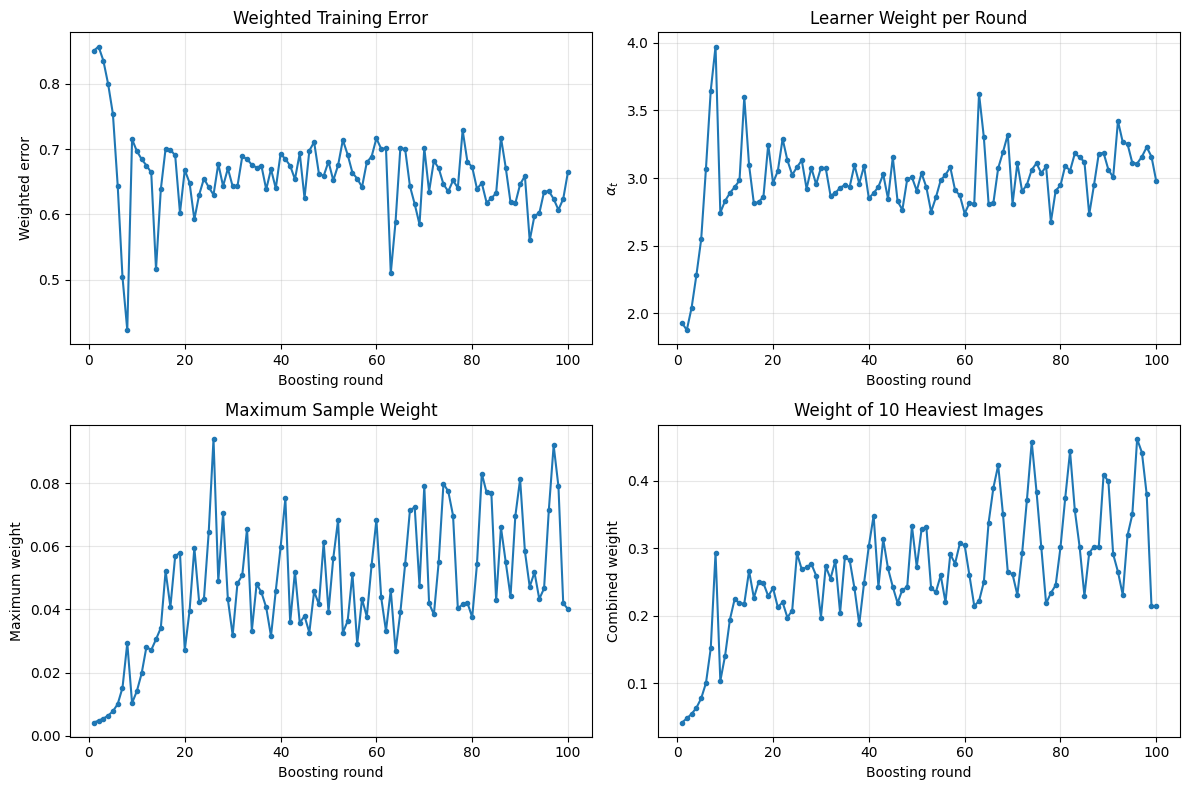

In [66]:
rounds = np.arange(1, len(boostingModel["trees"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plots = [
    (boostingModel["weighted_errors"],
     "Weighted Training Error", "Weighted error"),
    (boostingModel["alphas"],
     "Learner Weight per Round", r"$\alpha_t$"),
    (boostingModel["max_sample_weights"],
     "Maximum Sample Weight", "Maximum weight"),
    (boostingModel["top10_weight_sums"],
     "Weight of 10 Heaviest Images", "Combined weight")
]

for ax, (values, title, ylabel) in zip(axes.flat, plots):
    ax.plot(np.arange(1, len(values) + 1), values, marker=".")
    ax.set_title(title)
    ax.set_xlabel("Boosting round")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

(c) Compare boosting and bagging using 25, 50 and 100 learners. Report train, validation and clean test accuracy
and training time. Also inspect one training face that receives a very large boosting weight and use its prediction
history to explain why boosting repeatedly returns attention to that sample.

In [67]:
comparison_results = []

for B in [25, 50, 100]:
    # Bagging: train B trees from scratch
    start = perf_counter()
    bagged = bagging(
        X_train, y_train, B,
        rng=np.random.default_rng(26006)
    )
    bagging_time = perf_counter() - start
    bagged_trees = bagged["trees"]

    # Boosting: train B rounds using the selected depth
    start = perf_counter()
    boosted = train_samme(
        X_train, y_train,
        max_depth=MAX_DEPTH,
        n_rounds=B,
        random_state=26006
    )
    boosting_time = perf_counter() - start

    # Evaluate both models on all three splits
    for name, model_trees, predict_fn, train_time in [
        ("Bagging", bagged_trees, predict_bagging, bagging_time),
        ("SAMME", boosted, predict_samme, boosting_time)
    ]:
        def predict_current(X):
            if name == "Bagging":
                return predict_fn(model_trees, X)
            return predict_fn(model_trees, X)

        comparison_results.append({
            "Model": name,
            "Learners requested": B,
            "Learners trained": (
                len(model_trees) if name == "Bagging"
                else len(model_trees["trees"])
            ),
            "Train accuracy": np.mean(
                predict_current(X_train) == y_train
            ),
            "Validation accuracy": np.mean(
                predict_current(X_valid) == y_valid
            ),
            "Clean test accuracy": np.mean(
                predict_current(X_test) == y_test
            ),
            "Training time (s)": train_time
        })

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

,Model,Learners requested,Learners trained,Train accuracy,Validation accuracy,Clean test accuracy,Training time (s)
0,Bagging,25,25,1.000000,0.8500,0.7875,30.722221
1,SAMME,25,25,0.537500,0.2500,0.2875,8.708022
2,Bagging,50,50,1.000000,0.9000,0.8125,58.365694
3,SAMME,50,50,0.570833,0.2125,0.2000,17.648358
4,Bagging,100,100,1.000000,0.8875,0.8375,114.827799
5,SAMME,100,100,0.820833,0.3625,0.3750,34.995411


Training image index: 99
True identity: 16
Final sample weight: 0.030229346759314348


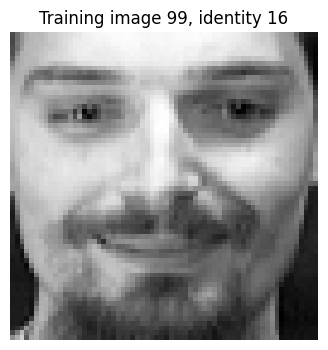

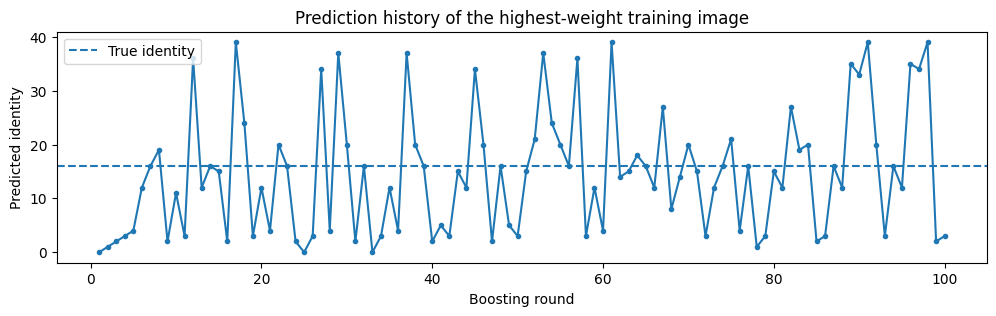

In [68]:
final_weights = boostingModel["final_sample_weights"]
idx = np.argmax(final_weights)

print("Training image index:", idx)
print("True identity:", y_train[idx])
print("Final sample weight:", final_weights[idx])

plt.figure(figsize=(4, 4))
plt.imshow(X_train[idx].reshape(64, 64), cmap="gray")
plt.title(f"Training image {idx}, identity {y_train[idx]}")
plt.axis("off")
plt.show()

# Track how successive weak learners classify this image
history = [
    tree.predict(X_train[idx:idx+1])[0]
    for tree in boostingModel["trees"]
]

plt.figure(figsize=(12, 3))
plt.plot(range(1, len(history) + 1), history, marker=".")
plt.axhline(y_train[idx], linestyle="--",
            label="True identity")
plt.xlabel("Boosting round")
plt.ylabel("Predicted identity")
plt.title("Prediction history of the highest-weight training image")
plt.legend()
plt.show()

Q2(c): Comparison of Bagging and SAMME Boosting

As can be seen, that Bagging outperformed SAMME boosting at all three ensemble sizes. With 50 learners, bagging achieved 100% training accuracy, 90% validation accuracy, and 81.25% clean test accuracy. SAMME with 50 rounds achieved 57.08%, 21.25%, and 20.00%, respectively. At 100 learners, SAMME's training accuracy increased to 82.08%, but its validation and test accuracies were only 36.25% and 37.50%.

The results show that increasing the number of boosting rounds improved training-set fit in this experiment but did not eliminate the generalization gap. The reported training times also differed: bagging took approximately 30.72, 58.37, and 114.83 seconds for 25, 50, and 100 learners, while SAMME took approximately 8.71, 17.65, and 35.00 seconds.

The training image with the highest final boosting weight was image 99, belonging to identity 16. Its final weight was approximately 0.03023, compared with an initial uniform weight of approximately 0.00417. The prediction history shows repeated misclassification across boosting rounds. This illustrates how SAMME increases the influence of difficult training examples so that subsequent weak learners pay more attention to them.

(d) Freeze the selected boosting model. Evaluate the single tree baseline, final bagged model and boosting model on
the clean and masked test sets. Report accuracy and mean winning vote or probability for each. Find one face
for which bagging and boosting respond differently to the missing region and explain the difference using tree
disagreement and boosting sample weighting.

In [69]:
# Saving model to local dir ./Models
joblib.dump(boostingModel, 'Models/boostingModel.joblib')

# Save configuration metadata for reproducibility
config = {
    "baseline_max_depth": None,
    "baseline_min_samples_leaf": 2,
    "bagging_max_depth": None,
    "bagging_min_samples_leaf": 2,
    "bagging_n_estimators": 50,
    "boosting_max_depth": 4,
    "boosting_n_rounds": 100,
    "random_seed": 26006
}

joblib.dump(config, "Models/model_config.joblib")

['Models/model_config.joblib']

In [71]:
# Evaluating the single tree baseline, final bagged model and boosting model on the clean and masked test sets
# Evaluating models on the clean test dataset
baseline_clean_accuracy = base_clean_accuracy
baseline_clean_confidence = base_clean_confidence

bagging_clean_accuracy = bagged_clean_accuracy
bagging_clean_confidence = bagged_clean_confidence

boosting_clean_accuracy = np.mean(predict_samme(boostingModel, X_test) == y_test)
boosting_clean_confidence = np.mean(predict_samme_confidence(boostingModel, X_test))

# Masked test set
baseline_masked_accuracy = base_masked_accuracy
baseline_masked_confidence = base_masked_confidence

bagging_masked_accuracy = bagged_masked_accuracy
bagging_masked_confidence = bagged_masked_confidence

boosting_masked_accuracy = np.mean(predict_samme(boostingModel, X_masked_test) == y_test)
boosting_masked_confidence = np.mean(predict_samme_confidence(boostingModel, X_masked_test))

# Results table
final_comparison_df = pd.DataFrame({
    "Model": ["Single Tree", "Bagging (B=50)", "SAMME AdaBoost"],
    "Clean Accuracy": [base_clean_accuracy, bagged_clean_accuracy, boosting_clean_accuracy],
    "Clean Mean Confidence": [
        base_clean_confidence, bagged_clean_confidence, boosting_clean_confidence
    ],
    "Masked Accuracy": [base_masked_accuracy, bagged_masked_accuracy, boosting_masked_accuracy],
    "Masked Mean Confidence": [
        base_masked_confidence, bagged_masked_confidence, boosting_masked_confidence
    ]
})

final_comparison_df

,Model,Clean Accuracy,Clean Mean Confidence,Masked Accuracy,Masked Mean Confidence
0,Single Tree,0.5500,0.97500,0.3000,0.950000
1,Bagging (B=50),0.8125,0.38850,0.5750,0.280500
2,SAMME AdaBoost,0.3750,0.12748,0.3875,0.123774


Q2(d): Clean and Masked Test Performance

The single decision tree achieved 55.00% accuracy on clean images and 30.00% on masked images. Bagging with 50 trees achieved 81.25% and 57.50%, respectively, outperforming the single tree under both conditions. SAMME with 100 rounds achieved 37.50% clean accuracy and 38.75% masked accuracy.

The single tree retained high mean predicted class probability under masking (95.00%), despite its low masked accuracy. This illustrates that a model's confidence does not necessarily indicate whether its prediction is correct. Bagging's mean winning-vote fraction decreased from 38.85% on clean images to 28.05% on masked images, suggesting that masking increased disagreement among its trees.

SAMME's mean normalized winning-vote fraction was lower, at 12.748% on clean images and 12.377% on masked images. These confidence measures have different definitions across models and should not be interpreted as calibrated probabilities. Overall, bagging provided the strongest recognition performance in this experiment, although masking reduced its accuracy substantially.

Candidate test indices: [ 1  2  3  5  6  7  8 13 14 17 19 21 25 26 27 28 32 33 41 44 45 46 48 50
 51 54 55 58 60 61 69 75 78 79]
Test index: 1
True identity: 0
Bagging clean/masked: 0 0
SAMME clean/masked: 3 12


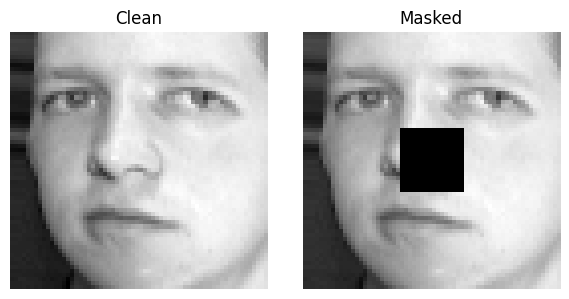

In [72]:
clean_bag = predict_bagging(final_bagged_trees, X_test)
masked_bag = predict_bagging(final_bagged_trees, X_masked_test)

clean_samme = predict_samme(boostingModel, X_test)
masked_samme = predict_samme(boostingModel, X_masked_test)

# Find images where masking changes one model's prediction
# but does not change the other model's prediction.
different_response = np.where(
    ((clean_bag != masked_bag) !=
     (clean_samme != masked_samme))
)[0]

print("Candidate test indices:", different_response)

if len(different_response):
    idx = different_response[0]
    print("Test index:", idx)
    print("True identity:", y_test[idx])
    print("Bagging clean/masked:", clean_bag[idx], masked_bag[idx])
    print("SAMME clean/masked:", clean_samme[idx], masked_samme[idx])

    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    axes[0].imshow(X_test[idx].reshape(64, 64), cmap="gray")
    axes[0].set_title("Clean")
    axes[1].imshow(X_masked_test[idx].reshape(64, 64), cmap="gray")
    axes[1].set_title("Masked")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No example found with this criterion.")

In [73]:
idx = 1

# Bagging vote counts for clean and masked images
clean_votes = get_bagging_votes(
    final_bagged_trees, X_test[idx:idx+1]
)[0]

masked_votes = get_bagging_votes(
    final_bagged_trees, X_masked_test[idx:idx+1]
)[0]

print("True identity:", y_test[idx])
print("\nBagging — clean votes:")
print({
    int(c): int(n)
    for c, n in zip(*np.unique(clean_votes, return_counts=True))
})

print("\nBagging — masked votes:")
print({
    int(c): int(n)
    for c, n in zip(*np.unique(masked_votes, return_counts=True))
})

# Count how many bagging trees change their prediction
print(
    "\nBagging trees whose predictions change:",
    np.sum(clean_votes != masked_votes),
    "out of", len(final_bagged_trees)
)

# SAMME: per-round predictions and learner weights
clean_round_preds = np.array([
    tree.predict(X_test[idx:idx+1])[0]
    for tree in boostingModel["trees"]
])

masked_round_preds = np.array([
    tree.predict(X_masked_test[idx:idx+1])[0]
    for tree in boostingModel["trees"]
])

alphas = np.asarray(boostingModel["alphas"])

print(
    "\nSAMME rounds whose predictions change:",
    np.sum(clean_round_preds != masked_round_preds),
    "out of", len(clean_round_preds)
)

print(
    "Total learner weight of changed rounds:",
    alphas[clean_round_preds != masked_round_preds].sum()
)

print(
    "Fraction of total learner weight in changed rounds:",
    alphas[clean_round_preds != masked_round_preds].sum() / alphas.sum()
)

True identity: 0

Bagging — clean votes:
{0: 15, 3: 3, 4: 1, 5: 2, 6: 2, 11: 1, 12: 1, 15: 3, 16: 2, 20: 6, 21: 1, 22: 1, 23: 3, 24: 1, 30: 2, 34: 2, 35: 3, 36: 1}

Bagging — masked votes:
{0: 9, 1: 1, 2: 1, 3: 1, 4: 1, 6: 1, 11: 1, 12: 4, 13: 9, 14: 1, 15: 3, 20: 4, 23: 2, 30: 2, 33: 1, 34: 2, 35: 6, 36: 1}

Bagging trees whose predictions change: 23 out of 50

SAMME rounds whose predictions change: 4 out of 100
Total learner weight of changed rounds: 11.355353234149899
Fraction of total learner weight in changed rounds: 0.03800402853302127


For test image 1, whose true identity was 0, bagging predicted identity 0 on both the clean and masked images, whereas SAMME changed its prediction from identity 3 to identity 12 after masking. This illustrates the different responses of the two ensemble methods to missing image information. Bagging combines the predictions of independently trained trees, allowing the majority vote to remain unchanged even when some individual predictions change. SAMME combines weak learners using their learned weights, so changes in the predictions of influential learners can affect the final classification.

The mean confidence results also show that confidence does not necessarily imply correctness. The single tree retained high mean predicted probability even when its masked test accuracy dropped substantially. Overall, bagging performed best in this experiment, although masking reduced its accuracy, indicating that ensemble aggregation can improve recognition performance but does not eliminate sensitivity to missing image regions.

Q3. Bias and variance as measured quantities 30 marks
Keep the final clean test set fixed. Create 30 new training sets by sampling with replacement, within each identity, six
faces from that identity’s original six training faces. Refit the selected single tree, the final bagged model and the
selected boosting model on each resampled set. Do not tune again. For repetition r, let pr(xi) be the class vector, p¯(xi) its mean over repetitions and ei the one hot target. For boosting use the normalised weighted vote vector. 

-   (a) Report measured bias squared and variance for the selected single tree, bagging and boosting models. Also report
the mean and standard deviation of test accuracy across the 30 refits.
-   (b) Repeat the calculation for single trees at one shallow depth, the selected depth and one much deeper depth. At
the same three depths build 100 tree bagged ensembles. Quantify how depth changes bias and variance, and how
much variance bagging removes at each depth.
-   (c) Determine whether the deepest tree is necessarily the depth at which bagging gives the largest improvement
in test accuracy. Your answer must use your measured bias, variance, leaf occupancy and disagreement results
rather than a generic statement about the bias variance tradeoff.
-   (d) End with one table for the selected single tree, bagging and boosting models containing clean test accuracy,
masked test accuracy, bias squared and variance. Using this table together with your earlier plots, explain which
model is most stable, which is most sensitive to the missing region, and whether the model with the lowest
variance is necessarily the model with the best test accuracy

In [75]:
CLASSES = np.arange(40)

def align_class_probabilities(model, X):
    """Return probability vectors with a fixed 40-class column order."""
    probabilities = model.predict_proba(X)
    aligned = np.zeros((len(X), len(CLASSES)))

    for j, class_label in enumerate(model.classes_):
        aligned[:, int(class_label)] = probabilities[:, j]

    return aligned

In [76]:
N_REPEATS = 30
N_IDENTITIES = 40
FACES_PER_IDENTITY = 6

# Keep a copy of the original training split.
X_train_original = X_train.copy()
y_train_original = y_train.copy()

rng_q3 = np.random.default_rng(26006)

resampled_train_sets = []

for repetition in range(N_REPEATS):
    X_resampled = []
    y_resampled = []

    for identity in range(N_IDENTITIES):
        identity_indices = np.flatnonzero(
            y_train_original == identity
        )

        sampled_indices = rng_q3.choice(
            identity_indices,
            size=FACES_PER_IDENTITY,
            replace=True
        )

        X_resampled.append(X_train_original[sampled_indices])
        y_resampled.append(y_train_original[sampled_indices])

    resampled_train_sets.append((
        np.vstack(X_resampled),
        np.concatenate(y_resampled)
    ))

print("Number of resampled datasets:", len(resampled_train_sets))
print("Shape of each resampled dataset:", resampled_train_sets[0][0].shape)

Number of resampled datasets: 30
Shape of each resampled dataset: (240, 4096)


In [80]:
def tree_class_vectors(model, X):
    """Class probability vectors for the single decision tree."""
    return align_class_probabilities(model, X)


def bagging_class_vectors(trees, X):
    """Normalized class-vote vectors for bagging."""
    votes = get_bagging_votes(trees, X)
    vectors = np.zeros((len(X), 40))

    for i, row in enumerate(votes):
        counts = np.bincount(row.astype(int), minlength=40)
        vectors[i] = counts / len(trees)

    return vectors


def samme_class_vectors(model, X):
    """Normalized weighted class-vote vectors for SAMME."""
    trees = model["trees"]
    alphas = np.asarray(model["alphas"], dtype=float)

    if len(trees) == 0 or alphas.sum() <= 0:
        raise ValueError("SAMME model has no valid weak learners.")

    vectors = np.zeros((len(X), 40))
    sample_indices = np.arange(len(X))

    for tree, alpha in zip(trees, alphas):
        predictions = tree.predict(X).astype(int)
        vectors[sample_indices, predictions] += alpha

    return vectors / alphas.sum()


In [83]:

N_JOBS = 3 
BAGGING_SIZE = 50
SAMME_DEPTH = 4
SAMME_ROUNDS = 100

X_test_fixed = X_test.copy()
y_test_fixed = y_test.copy()

def run_one_repetition(r, X_r, y_r):
    # Use independent, reproducible seeds for each repetition
    seed = 26006 + r

    # 1. Single decision tree
    tree_r = DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=2,
        random_state=seed
    )
    tree_r.fit(X_r, y_r)
    tree_vectors = tree_class_vectors(tree_r, X_test_fixed)

    # 2. Bagging ensemble
    bagging_r = bagging(
        X_r,
        y_r,
        n_estimators=BAGGING_SIZE,
        rng=np.random.default_rng(seed)
    )
    bagging_vectors = bagging_class_vectors(
        bagging_r["trees"], X_test_fixed
    )

    # 3. SAMME boosting
    boosting_r = train_samme(
        X_r,
        y_r,
        max_depth=SAMME_DEPTH,
        n_rounds=SAMME_ROUNDS,
        random_state=seed
    )
    boosting_vectors = samme_class_vectors(
        boosting_r, X_test_fixed
    )

    return r, tree_vectors, bagging_vectors, boosting_vectors


results = Parallel(
    n_jobs=N_JOBS,
    backend="loky",
    verbose=10
)(
    delayed(run_one_repetition)(r, X_r, y_r)
    for r, (X_r, y_r) in enumerate(resampled_train_sets)
)

# Restore repetition order and stack the outputs
results.sort(key=lambda item: item[0])

tree_vectors_all = np.stack([item[1] for item in results])
bagging_vectors_all = np.stack([item[2] for item in results])
boosting_vectors_all = np.stack([item[3] for item in results])

print("Tree:", tree_vectors_all.shape)
print("Bagging:", bagging_vectors_all.shape)
print("Boosting:", boosting_vectors_all.shape)


[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done   2 tasks      | elapsed:  1.7min
[Parallel(n_jobs=3)]: Done   7 tasks      | elapsed:  4.8min
[Parallel(n_jobs=3)]: Done  12 tasks      | elapsed:  6.6min
[Parallel(n_jobs=3)]: Done  19 tasks      | elapsed: 11.2min
[Parallel(n_jobs=3)]: Done  30 out of  30 | elapsed: 16.5min finished


Tree: (30, 80, 40)
Bagging: (30, 80, 40)
Boosting: (30, 80, 40)


In [88]:

def measure_bias_variance(vectors_all, y_true):
    """
    vectors_all: (repetitions, test_samples, classes)
    y_true:      true identity for each test sample
    """
    n_repeats, n_samples, n_classes = vectors_all.shape

    mean_vectors = vectors_all.mean(axis=0)
    one_hot = np.eye(n_classes)[y_true]

    bias_squared = np.mean(
        np.sum((mean_vectors - one_hot) ** 2, axis=1)
    )

    variance = np.mean(
        np.sum(
            (vectors_all - mean_vectors[None, :, :]) ** 2,
            axis=2
        )
    )

    predictions = np.argmax(vectors_all, axis=2)
    accuracies = np.mean(predictions == y_true[None, :], axis=1)

    return {
        "Bias squared": bias_squared,
        "Variance": variance,
        "Mean test accuracy (%)": accuracies.mean() * 100,
        "Std test accuracy (percentage points)": (
            accuracies.std(ddof=1) * 100
        )
    }


In [89]:
q3a_results = pd.DataFrame({
    "Single tree": measure_bias_variance(
        tree_vectors_all, y_test_fixed
    ),
    "Bagging (B=50)": measure_bias_variance(
        bagging_vectors_all, y_test_fixed
    ),
    "SAMME (depth=4, rounds=100)": measure_bias_variance(
        boosting_vectors_all, y_test_fixed
    )
}).T

display(q3a_results.round(4))

,Bias squared,Variance,Mean test accuracy (%),Std test accuracy (percentage points)
Single tree,0.4370,0.6495,45.6667,6.1565
Bagging (B=50),0.5311,0.0335,73.0000,4.3624
"SAMME (depth=4, rounds=100)",0.8839,0.0166,35.5417,7.0991


### Q3(a): Results
Across the 30 resampled training sets, bagging achieved the highest mean test accuracy of 73.00%, compared with 45.67% for the single decision tree and 35.54% for SAMME. Bagging reduced the measured variance from 0.6495 to 0.0335, a reduction of approximately 94.8%, while also reducing the standard deviation of test accuracy from 6.16 to 4.36 percentage points. This indicates that aggregating decision trees substantially improved both predictive performance and stability under training-set resampling.

SAMME exhibited the lowest measured variance (0.0166), but its mean test accuracy was also the lowest, and its measured bias squared was the highest (0.8839). This demonstrates that low variance alone does not guarantee high predictive accuracy. The ensemble's predictions can remain relatively consistent while still being systematically incorrect. The measured bias-squared values should be interpreted in conjunction with accuracy because the models use different class-vector representations.

In [91]:
DEPTHS = [2, 8, None]
BAGGING_SIZE_Q3B = 100
N_JOBS_Q3B = 4

X_test_fixed = X_test.copy()
y_test_fixed = y_test.copy()
N_CLASSES = 40


def bagging_at_depth(X, y, n_estimators, max_depth, seed):
    """Train a bootstrap ensemble using the specified tree depth."""
    rng = np.random.default_rng(seed)
    n_samples = len(y)
    trees = []

    for _ in range(n_estimators):
        indices = rng.choice(n_samples, size=n_samples, replace=True)
        tree_seed = int(rng.integers(0, 2**31 - 1))

        model = DecisionTreeClassifier(
            max_depth=max_depth,
            min_samples_leaf=2,
            random_state=tree_seed
        )
        model.fit(X[indices], y[indices])
        trees.append(model)

    return trees


def tree_vote_vectors(trees, X):
    """Return normalized class-vote vectors for a bagged ensemble."""
    votes = np.array([tree.predict(X) for tree in trees]).T
    vectors = np.zeros((len(X), N_CLASSES))

    for i, row in enumerate(votes):
        vectors[i] = (
            np.bincount(row.astype(int), minlength=N_CLASSES)
            / len(trees)
        )

    return vectors


def leaf_occupancy(model, X):
    """Measure leaf occupancy on the supplied training data."""
    leaf_ids = model.apply(X)
    _, counts = np.unique(leaf_ids, return_counts=True)

    return {
        "leaf_count": len(counts),
        "mean_samples_per_leaf": float(counts.mean()),
        "singleton_leaf_fraction": float(np.mean(counts == 1))
    }


def pairwise_disagreement(trees, X):
    """Mean pairwise prediction disagreement on X."""
    predictions = np.array([tree.predict(X) for tree in trees])
    n_trees = predictions.shape[0]

    if n_trees < 2:
        return 0.0

    # For each test example, calculate the fraction of disagreeing pairs.
    total_pairs = n_trees * (n_trees - 1) / 2
    disagreements = []

    for row in predictions.T:
        _, counts = np.unique(row, return_counts=True)
        agreeing_pairs = np.sum(counts * (counts - 1) / 2)
        disagreements.append(
            (total_pairs - agreeing_pairs) / total_pairs
        )

    return float(np.mean(disagreements))


def run_depth_repetition(depth, r, X_r, y_r):
    """Run one repetition for one depth; safe to parallelize."""
    seed = 26006 + r

    # Single tree
    single = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=2,
        random_state=seed
    )
    single.fit(X_r, y_r)

    single_vectors = tree_class_vectors(single, X_test_fixed)
    single_accuracy = np.mean(
        np.argmax(single_vectors, axis=1) == y_test_fixed
    )
    single_occ = leaf_occupancy(single, X_r)

    # Bagged ensemble
    trees = bagging_at_depth(
        X_r, y_r,
        n_estimators=BAGGING_SIZE_Q3B,
        max_depth=depth,
        seed=seed
    )

    bagged_vectors = tree_vote_vectors(trees, X_test_fixed)
    bagged_accuracy = np.mean(
        np.argmax(bagged_vectors, axis=1) == y_test_fixed
    )

    # Average occupancy across the 100 constituent trees
    occs = [leaf_occupancy(tree, X_r) for tree in trees]

    bagged_occ = {
        "leaf_count": np.mean([o["leaf_count"] for o in occs]),
        "mean_samples_per_leaf": np.mean(
            [o["mean_samples_per_leaf"] for o in occs]
        ),
        "singleton_leaf_fraction": np.mean(
            [o["singleton_leaf_fraction"] for o in occs]
        )
    }

    disagreement = pairwise_disagreement(trees, X_test_fixed)

    return {
        "depth": depth,
        "repetition": r,
        "single_vectors": single_vectors,
        "bagged_vectors": bagged_vectors,
        "single_accuracy": single_accuracy,
        "bagged_accuracy": bagged_accuracy,
        "single_occ": single_occ,
        "bagged_occ": bagged_occ,
        "disagreement": disagreement
    }


# Run the independent depth/repetition combinations concurrently.
tasks = [
    (depth, r, X_r, y_r)
    for depth in DEPTHS
    for r, (X_r, y_r) in enumerate(resampled_train_sets)
]

parallel_results = Parallel(
    n_jobs=N_JOBS_Q3B,
    backend="loky",
    verbose=10
)(
    delayed(run_depth_repetition)(depth, r, X_r, y_r)
    for depth, r, X_r, y_r in tasks
)

print(f"Completed {len(parallel_results)} depth/repetition jobs.")

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   36.1s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   51.7s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:  1.4min
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:  1.7min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  3.1min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  5.1min
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:  8.1min
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed: 12.5min
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed: 21.1min
[Parallel(n_jobs=4)]: Done  90 out of  90 | elapsed: 28.5min finished


Completed 90 depth/repetition jobs.


In [ ]:

depth_results = {}

for depth in DEPTHS:
    items = sorted(
        [x for x in parallel_results if x["depth"] == depth],
        key=lambda x: x["repetition"]
    )

    single_vectors = np.stack(
        [x["single_vectors"] for x in items]
    )
    bagged_vectors = np.stack(
        [x["bagged_vectors"] for x in items]
    )

    single_metrics = measure_bias_variance(
        single_vectors, y_test_fixed
    )
    bagged_metrics = measure_bias_variance(
        bagged_vectors, y_test_fixed
    )

    depth_results[depth] = {
        "single_vectors": single_vectors,
        "bagged_vectors": bagged_vectors,
        "single_metrics": single_metrics,
        "bagged_metrics": bagged_metrics,

        "single_accuracy_mean": np.mean(
            [x["single_accuracy"] for x in items]
        ) * 100,
        "single_accuracy_std": np.std(
            [x["single_accuracy"] for x in items], ddof=1
        ) * 100,

        "bagged_accuracy_mean": np.mean(
            [x["bagged_accuracy"] for x in items]
        ) * 100,
        "bagged_accuracy_std": np.std(
            [x["bagged_accuracy"] for x in items], ddof=1
        ) * 100,

        "single_leaf_count": np.mean([
            x["single_occ"]["leaf_count"] for x in items
        ]),
        "single_mean_occupancy": np.mean([
            x["single_occ"]["mean_samples_per_leaf"] for x in items
        ]),
        "single_singleton_fraction": np.mean([
            x["single_occ"]["singleton_leaf_fraction"] for x in items
        ]),

        "bagged_leaf_count": np.mean([
            x["bagged_occ"]["leaf_count"] for x in items
        ]),
        "bagged_mean_occupancy": np.mean([
            x["bagged_occ"]["mean_samples_per_leaf"] for x in items
        ]),
        "bagged_singleton_fraction": np.mean([
            x["bagged_occ"]["singleton_leaf_fraction"] for x in items
        ]),
        "bagged_disagreement": np.mean([
            x["disagreement"] for x in items
        ])
    }

print("Q3(b) results reconstructed successfully.")


Q3(b) results reconstructed successfully.


In [93]:
rows = []

for depth in DEPTHS:
    result = depth_results[depth]
    sm = result["single_metrics"]
    bm = result["bagged_metrics"]

    rows.append({
        "Depth": str(depth),
        "Model": "Single tree",
        "Bias squared": sm["Bias squared"],
        "Variance": sm["Variance"],
        "Mean accuracy (%)": result["single_accuracy_mean"],
        "Accuracy SD (pp)": result["single_accuracy_std"],
        "Mean leaves": result["single_leaf_count"],
        "Mean samples/leaf": result["single_mean_occupancy"],
        "Singleton leaf fraction": result["single_singleton_fraction"],
        "Pairwise disagreement": np.nan
    })

    rows.append({
        "Depth": str(depth),
        "Model": "Bagging (B=100)",
        "Bias squared": bm["Bias squared"],
        "Variance": bm["Variance"],
        "Mean accuracy (%)": result["bagged_accuracy_mean"],
        "Accuracy SD (pp)": result["bagged_accuracy_std"],
        "Mean leaves": result["bagged_leaf_count"],
        "Mean samples/leaf": result["bagged_mean_occupancy"],
        "Singleton leaf fraction": result["bagged_singleton_fraction"],
        "Pairwise disagreement": result["bagged_disagreement"]
    })

q3b_table = pd.DataFrame(rows)
display(q3b_table.round(4))

,Depth,Model,Bias squared,Variance,Mean accuracy (%),Accuracy SD (pp),Mean leaves,Mean samples/leaf,Singleton leaf fraction,Pairwise disagreement
0,2,Single tree,0.9174,0.0446,5.7917,1.2493,3.0667,78.6667,0.0000,NaN
1,2,Bagging (B=100),0.9309,0.0112,15.8333,4.8505,3.1287,77.4267,0.0011,0.9614
2,8,Single tree,0.7859,0.1332,16.2917,2.5740,9.3333,25.7778,0.0000,NaN
3,8,Bagging (B=100),0.8063,0.0163,48.1250,6.8130,10.6950,22.8120,0.0045,0.9289
4,None,Single tree,0.4370,0.6495,45.6667,6.1565,40.0667,5.9902,0.0000,NaN
5,None,Bagging (B=100),0.5297,0.0248,74.6250,4.0224,44.6567,5.3846,0.0127,0.8316


In [94]:
variance_rows = []

for depth in DEPTHS:
    result = depth_results[depth]

    single_var = result["single_metrics"]["Variance"]
    bagged_var = result["bagged_metrics"]["Variance"]

    reduction_pct = (
        100 * (single_var - bagged_var) / single_var
        if single_var > 0 else np.nan
    )

    variance_rows.append({
        "Depth": str(depth),
        "Single-tree variance": single_var,
        "Bagged variance": bagged_var,
        "Variance reduction (%)": reduction_pct,
        "Single-tree accuracy (%)": result["single_accuracy_mean"],
        "Bagged accuracy (%)": result["bagged_accuracy_mean"],
        "Accuracy improvement (pp)": (
            result["bagged_accuracy_mean"]
            - result["single_accuracy_mean"]
        )
    })

variance_comparison = pd.DataFrame(variance_rows)
display(variance_comparison.round(4))

,Depth,Single-tree variance,Bagged variance,Variance reduction (%),Single-tree accuracy (%),Bagged accuracy (%),Accuracy improvement (pp)
0,2,0.0446,0.0112,74.7964,5.7917,15.8333,10.0417
1,8,0.1332,0.0163,87.7952,16.2917,48.1250,31.8333
2,None,0.6495,0.0248,96.1785,45.6667,74.6250,28.9583


### Q3(b): Effect of Tree Depth on Bias, Variance, and Bagging
As tree depth increases, bias decreases but variance increases, making individual trees more sensitive to the training data. Bagging reduces variance at every depth, with the largest reduction of approximately 96.2% for unrestricted trees. It also improves test accuracy at all three depths. The unrestricted trees achieve the highest bagged accuracy of 74.63%, showing that deeper trees can learn more useful distinctions between identities when their predictions are aggregated.

### Q3(c): Does the Deepest Tree Necessarily Yield the Largest Improvement from Bagging?
The deepest tree does not necessarily benefit the most from bagging in terms of accuracy improvement. The depth-8 tree gains 31.83 percentage points, compared with 28.96 percentage points for unrestricted trees and 10.04 percentage points for depth 2.

The unrestricted tree has the highest variance (0.6495), which bagging reduces by 96.2%, but depth 8 still achieves the largest accuracy gain. Leaf occupancy decreases from about 78.67 samples per leaf at depth 2 to 25.78 at depth 8 and 5.99 for unrestricted trees, allowing deeper trees to form more specific decision regions. Pairwise disagreement also decreases with depth, from 0.9614 to 0.9289 and 0.8316. The shallow trees disagree most, but their accuracy is too low for this diversity to translate into strong predictions.

Overall, depth 8 gets the largest improvement from bagging, while unrestricted trees achieve the highest final accuracy. The benefit of bagging depends on the combination of bias, variance, leaf structure and disagreement—not just tree depth or variance alone.

In [95]:
q3d_table = pd.DataFrame([
    {
        "Model": "Single decision tree",
        "Clean accuracy (%)": 55.00,
        "Masked accuracy (%)": 30.00,
        "Bias squared": 0.4370,
        "Variance": 0.6495
    },
    {
        "Model": "Bagging (B=50)",
        "Clean accuracy (%)": 81.25,
        "Masked accuracy (%)": 57.50,
        "Bias squared": 0.5311,
        "Variance": 0.0335
    },
    {
        "Model": "SAMME boosting (depth=4, rounds=100)",
        "Clean accuracy (%)": 37.50,
        "Masked accuracy (%)": 38.75,
        "Bias squared": 0.8839,
        "Variance": 0.0166
    }
])

display(q3d_table.round(4))

,Model,Clean accuracy (%),Masked accuracy (%),Bias squared,Variance
0,Single decision tree,55.00,30.00,0.4370,0.6495
1,Bagging (B=50),81.25,57.50,0.5311,0.0335
2,"SAMME boosting (depth=4, rounds=100)",37.50,38.75,0.8839,0.0166


### Q3(d): Final Comparison of Single Tree, Bagging, and Boosting

Bagging is the most effective overall, achieving the highest accuracy on both test sets while significantly reducing variance compared to a single tree. The single tree is the most sensitive to the missing region, with accuracy dropping by 25 percentage points. SAMME has the lowest variance, making its predictions more stable across different training resamples, but its accuracy remains the lowest. So, the model with the lowest variance is not necessarily the model with the best test accuracy; stability alone does not guarantee good predictions.

In [97]:
import numpy
import sklearn
import matplotlib
import pandas
import joblib
import IPython

print("numpy:", numpy.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)
print("pandas:", pandas.__version__)
print("joblib:", joblib.__version__)
print("IPython:", IPython.__version__)

numpy: 2.5.3
scikit-learn: 1.5.2
matplotlib: 3.10.9
pandas: 3.0.3
joblib: 1.4.2
IPython: 8.26.0
